# **Self-RAG Step 2: Document Relevance Evaluation**

![Self-RAG Retrieve, Verify, Generate.png](<attachment:Self-RAG Retrieve, Verify, Generate.png>)

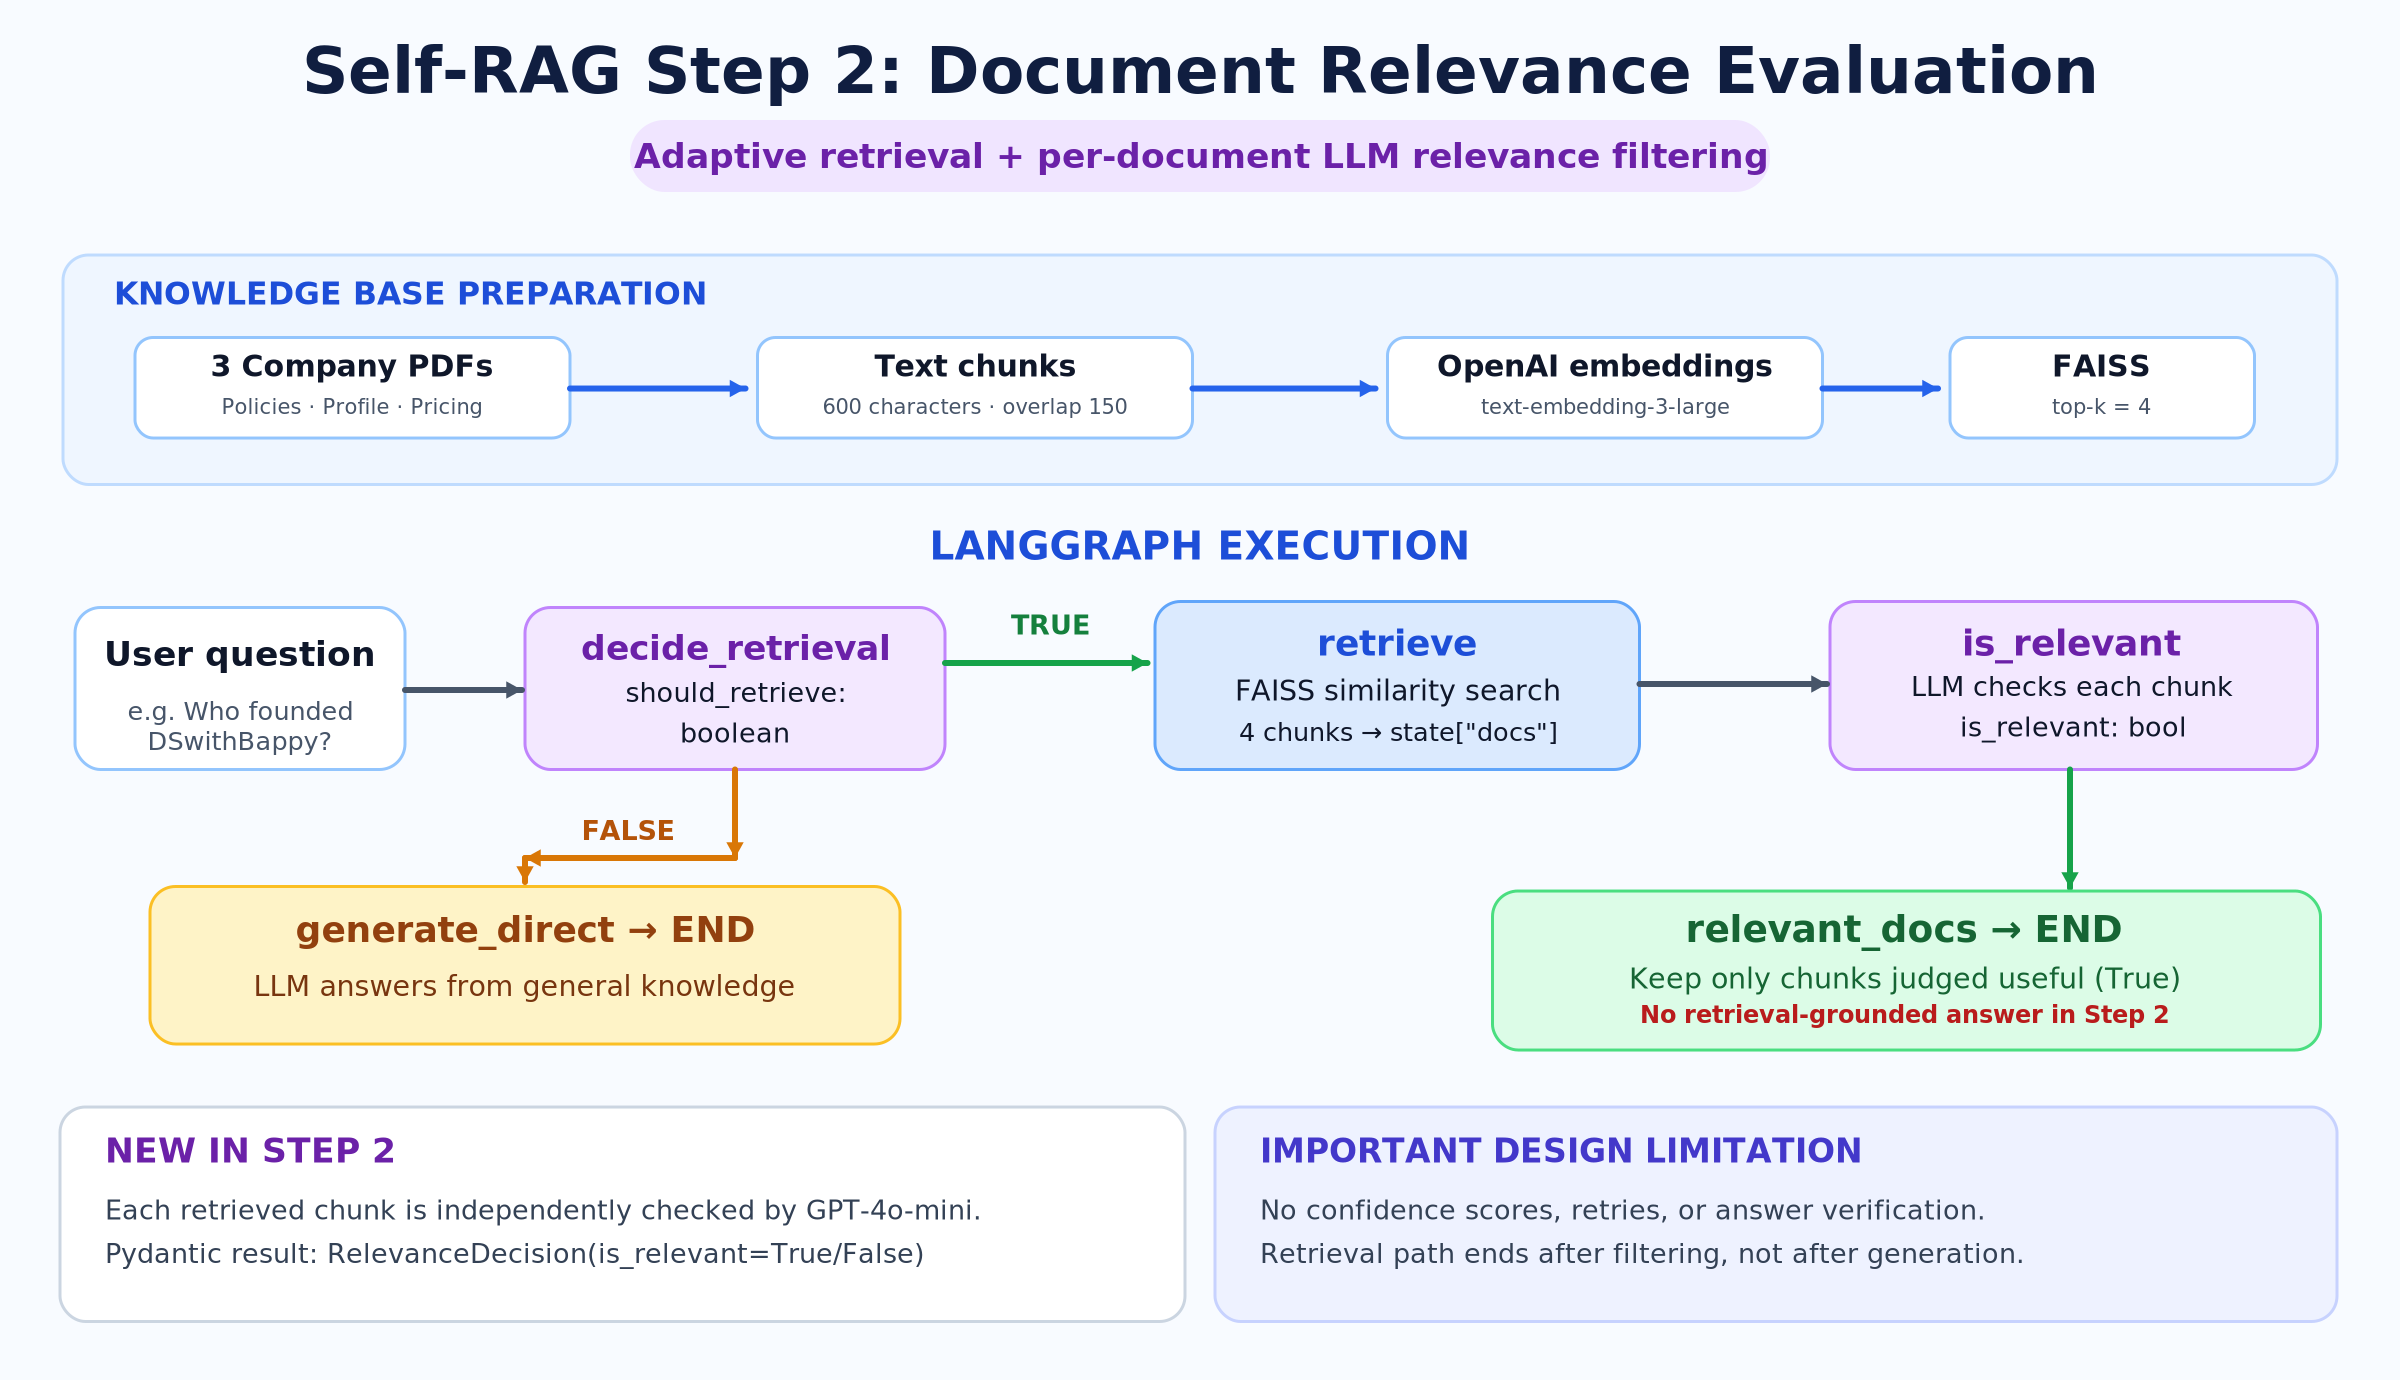

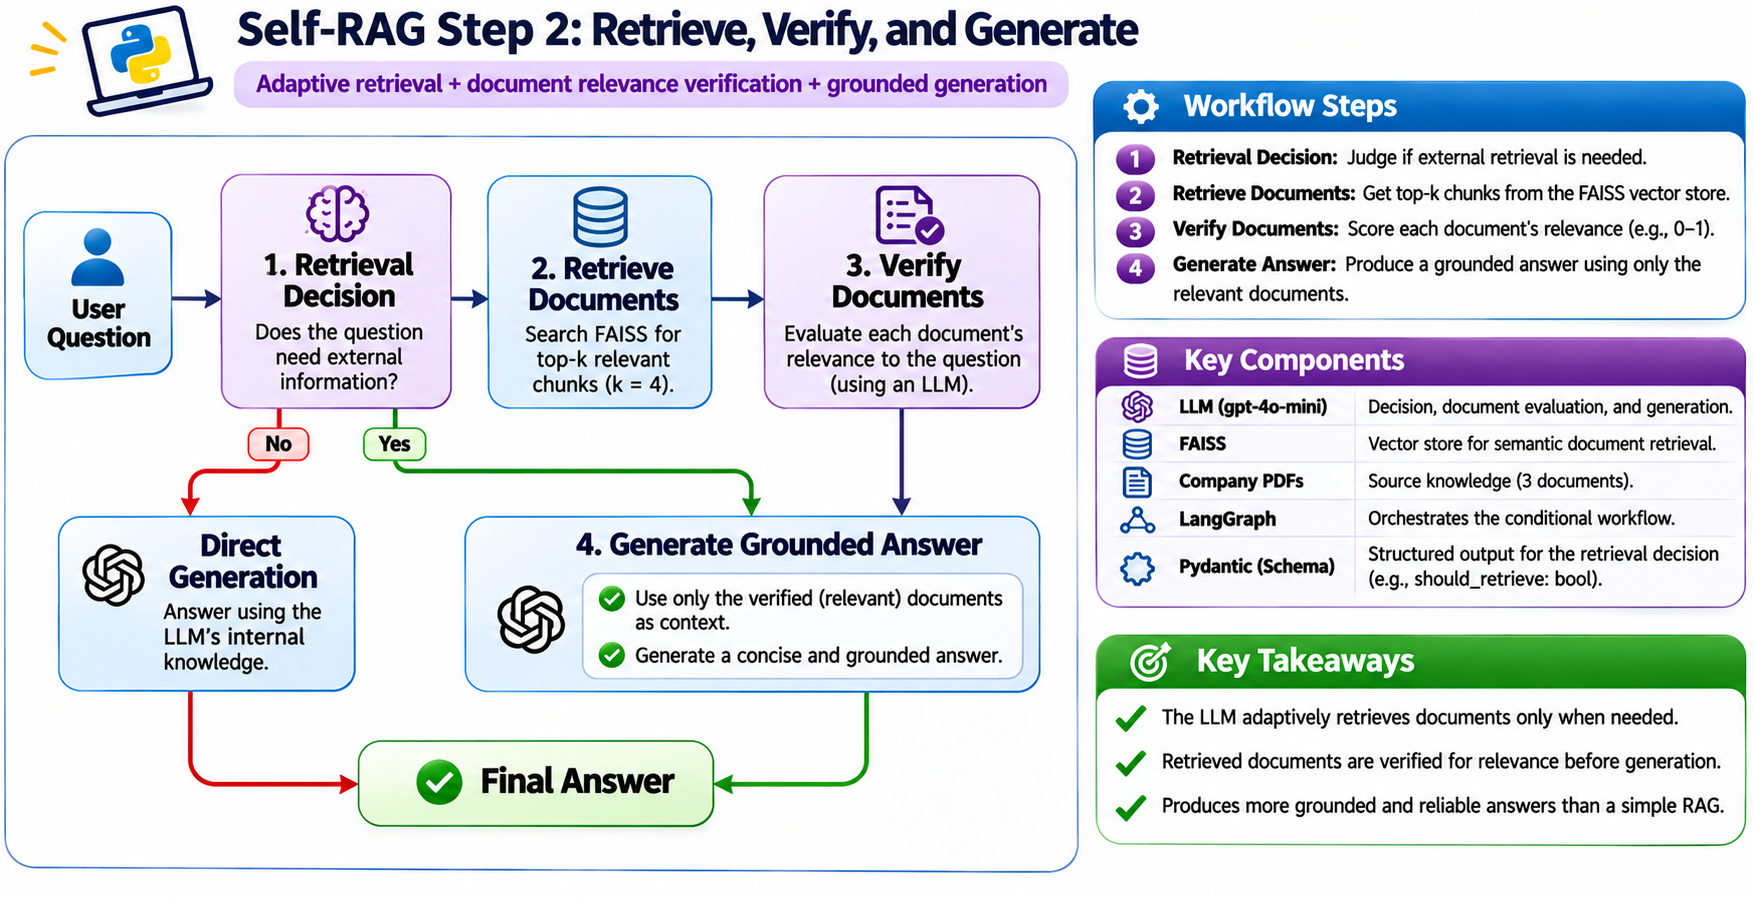

This notebook extends Self-RAG Step 1 by introducing **LLM-based document relevance evaluation** using LangGraph, FAISS, and GPT-4o-mini.

### 1. Knowledge Base Preparation

- Load three company PDF documents using `PyPDFLoader`.
- Split documents into chunks (`chunk_size=600`, `chunk_overlap=150`).
- Generate embeddings using `text-embedding-3-large`.
- Store embeddings in FAISS and retrieve the top 4 chunks.

### 2. Adaptive Retrieval

The `decide_retrieval()` node determines whether external knowledge is required.

```python
class RetrieveDecision(BaseModel):
    should_retrieve: bool
```

- **False:** Generate an answer directly using the LLM.
- **True:** Retrieve documents from FAISS.

### 3. Document Relevance Evaluation (New)

The `is_relevant()` node evaluates each retrieved document against the user question.

```python
class RelevanceDecision(BaseModel):
    is_relevant: bool
```

Each document receives a Boolean decision:

- `True`: Keep the document.
- `False`: Discard the document.

Accepted documents are stored in `state["relevant_docs"]`.

### 4. LangGraph Workflow

```text
START → decide_retrieval
               │
        ┌──────┴──────┐
        ▼             ▼
      False          True
        │             │
 generate_direct   retrieve
        │             │
       END        is_relevant
                      │
                     END
```

### 5. Key Takeaway

**Self-RAG Step 2 adds a relevance judgment after retrieval, preventing irrelevant documents from being automatically accepted as evidence.**

Unlike Step 1, the system now filters retrieved documents using an LLM.

**Current limitation:** The retrieval branch ends after document evaluation. Generating a grounded answer from `relevant_docs` and evaluating the answer itself are future steps.

In [10]:
import os
from typing import List, TypedDict, Literal
from pydantic import BaseModel, Field

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

# Load API credentials and configuration from the project .env file.
load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("BASE_URL")

In [11]:
# Set False to rebuild the FAISS index from the source PDFs; True loads the saved index.
faiss_saved = True

# Build and save the index when no reusable local index is selected.
if faiss_saved==False:
    # Load the company policy, profile, and pricing PDFs as LangChain Documents.
    docs = (
        PyPDFLoader("./documents/DSwithBappy_Company_Policies.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Company_Profile.pdf").load()
        + PyPDFLoader("./documents/DSwithBappy_Product_and_Pricing.pdf").load()

    )
    # Split long documents into overlapping passages for retrieval.
    chunks = RecursiveCharacterTextSplitter(
    chunk_size=600, chunk_overlap=150
    ).split_documents(docs)
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Embed the chunks and build a FAISS similarity-search index.
    vector_store = FAISS.from_documents(chunks, hf_embeddings)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})
    
else:
    # Create the sentence-transformer encoder used for document and query vectors.
    hf_embeddings = HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2')
    # Restore the saved FAISS index; only load an index you trust.
    vector_store = FAISS.load_local("faiss_index", hf_embeddings, allow_dangerous_deserialization=True)
    # Configure retrieval to return the four nearest chunks per query.
    retriever = vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})


In [12]:
docs = retriever.invoke("what is DSwithBappy company profile?")
print(docs)

[Document(id='f341c2d6-90a8-49e8-8fcb-00ad0fdf158f', metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creator': '(unspecified)', 'creationdate': '2026-08-26T04:40:11+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-08-26T04:40:11+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': './documents/DSwithBappy_Company_Profile.pdf', 'total_pages': 2, 'page': 0, 'page_label': '1'}, page_content='DSwithBappy - Company Profile\nCompany Overview\nDSwithBappy is an AI education and engineering platform focused on helping learners build\npractical, production-ready skills in artificial intelligence.\nThe platform specializes in hands-on learning across Generative AI, RAG, Agentic AI, LLM\napplications, AI engineering, and deployment.\nDSwithBappy serves students, developers, working professionals, and teams who want to learn\nmodern AI through practical projects and clear explanations.\n●\nFocus: Practical AI education and engin

In [13]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0, api_key=api_key, base_url=base_url)

In [14]:
# --------------------------------------------------
# Graph State
# --------------------------------------------------
class State(TypedDict):
    question: str
    need_retrieval: bool

    docs: List[Document]
    relevant_docs: List[Document]     # New

    answer: str

In [15]:
# Structured model result for deciding whether retrieval is needed.
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )

decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)


# IMPORTANT: no `.content` for structured output
should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: "State"):
    # Decide whether this question needs facts from the local documents.
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    # Store the retrieval decision in the graph state for routing.
    return {"need_retrieval": decision.should_retrieve}

In [16]:
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)


# Answer general questions without consulting the document collection.
def generate_direct(state: State):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )
    return {
        "answer": out.content
    }


In [17]:
# Search the FAISS index using the rewritten query when available.
def retrieve(state: State):
    # Save retrieved document chunks in graph state.
    return {"docs": retriever.invoke(state["question"])}

In [18]:
# New

# Structured yes/no judgment for each retrieved document.
class RelevanceDecision(BaseModel):
    is_relevant: bool = Field(
        ...,
        description="True if the document helps answer the question, else False."
    )

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are judging document relevance.\n"
            "Return JSON that matches this schema:\n"
            "{{'is_relevant': boolean}}\n\n"
            "A document is relevant if it contains information useful for answering the question."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        ),
    ]
)

# Return a validated relevance decision instead of free-form text.
relevance_llm = llm.with_structured_output(RelevanceDecision)

def is_relevant(state: State):
    
    relevant_docs: List[Document] = []

    # Evaluate each retrieved chunk against the original question.
    for doc in state["docs"]:
        decision: RelevanceDecision = relevance_llm.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content
            )
        )

        # Keep only documents the model considers useful evidence.
        if decision.is_relevant:
            relevant_docs.append(doc)

    # Pass the filtered evidence to the next graph node.
    return {"relevant_docs": relevant_docs}



In [19]:
# Select direct answering or retrieval based on the decision in state.
def route_after_decide(state: State) -> Literal["generate_direct", "retrieve"]:
    if state["need_retrieval"]:
        return "retrieve"
    return "generate_direct"

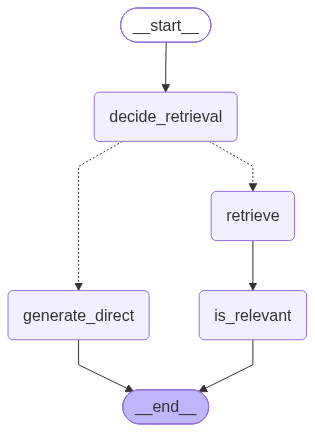

In [20]:
# Create the LangGraph workflow with the shared state schema.
g = StateGraph(State)

# --------------------
# Nodes
# --------------------
g.add_node("decide_retrieval", decide_retrieval)
g.add_node("generate_direct", generate_direct)
g.add_node("retrieve", retrieve)
g.add_node("is_relevant", is_relevant) # New

# --------------------
# Edges
# --------------------
g.add_edge(START, "decide_retrieval")

# Add a decision-based branch in the workflow.
g.add_conditional_edges(
    "decide_retrieval",
    route_after_decide,
    {
        "generate_direct": "generate_direct",
        "retrieve": "retrieve",
    },
)

g.add_edge("generate_direct", END)
g.add_edge("retrieve", "is_relevant") # New
g.add_edge("is_relevant", END) # New

# Compile the nodes and edges into an executable graph.
app = g.compile()
app

In [21]:
# Run the complete Self-RAG workflow for the supplied state.
result = app.invoke(
    {
        "question": "Who is the Founder of DSwithBappy",
        "need_retrieval": False,
        "docs": [],
        "answer": "",
    }
)

print(result["answer"])

In [22]:
result['need_retrieval']

True

In [23]:
for doc in result['docs']:
    print(doc.page_content)
    print("*"*100)

DSwithBappy - Company Profile
Company Overview
DSwithBappy is an AI education and engineering platform focused on helping learners build
practical, production-ready skills in artificial intelligence.
The platform specializes in hands-on learning across Generative AI, RAG, Agentic AI, LLM
applications, AI engineering, and deployment.
DSwithBappy serves students, developers, working professionals, and teams who want to learn
modern AI through practical projects and clear explanations.
●
Focus: Practical AI education and engineering
●
Learning Model: Theory + hands-on implementation
●
****************************************************************************************************
Founder
Bappy founded DSwithBappy with the goal of making modern AI engineering easier to
understand through practical, step-by-step learning.
Through technical tutorials, courses, end-to-end projects, and community content, DSwithBappy
focuses on helping learners turn AI concepts into working applications.
P

In [24]:
for doc in result['relevant_docs']:
    print(doc.page_content)
    print("*"*100)

Founder
Bappy founded DSwithBappy with the goal of making modern AI engineering easier to
understand through practical, step-by-step learning.
Through technical tutorials, courses, end-to-end projects, and community content, DSwithBappy
focuses on helping learners turn AI concepts into working applications.
Platform & Learning Team
DSwithBappy brings together content creation, AI engineering, course development, project
building, and learner support to create a practical learning experience.
●
AI Engineering & Project Development
●
Course and Curriculum Development
●
****************************************************************************************************


In [24]:
result['relevant_docs']

[Document(id='efe6a25d-fc9f-42c3-aed7-fcf2804ac0ff', metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creator': '(unspecified)', 'creationdate': '2026-08-26T04:40:11+00:00', 'author': '(anonymous)', 'keywords': '', 'moddate': '2026-08-26T04:40:11+00:00', 'subject': '(unspecified)', 'title': '(anonymous)', 'trapped': '/False', 'source': './documents/DSwithBappy_Company_Profile.pdf', 'total_pages': 2, 'page': 1, 'page_label': '2'}, page_content='Founder\nBappy founded DSwithBappy with the goal of making modern AI engineering easier to\nunderstand through practical, step-by-step learning.\nThrough technical tutorials, courses, end-to-end projects, and community content, DSwithBappy\nfocuses on helping learners turn AI concepts into working applications.\nPlatform & Learning Team\nDSwithBappy brings together content creation, AI engineering, course development, project\nbuilding, and learner support to create a practical learning experience.\n●\nAI Engineering & Project Devel